# Week 3 — Exploratory Data Analysis & Visualization

SwiftRoute Logistics is a hypothetical case study. This notebook analyzes the supplied 500-row simulated shipment dataset. Run from this notebook's folder; the dataset path is `../data/SwiftRoute_Logistics_Dataset.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("../data/SwiftRoute_Logistics_Dataset.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["Order_Date"])
expected_columns = [
    "Shipment_ID", "Order_Date", "Distance_KM", "Shipment_Weight_KG",
    "Shipment_Volume", "Delivery_Time_Days", "Delivery_Zone",
    "Delivery_Status", "Transportation_Cost"
]
missing = sorted(set(expected_columns) - set(df.columns))
if missing:
    raise ValueError(f"Missing expected columns: {missing}")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (500, 9)


,Shipment_ID,Order_Date,Distance_KM,Shipment_Weight_KG,Shipment_Volume,Delivery_Time_Days,Delivery_Zone,Delivery_Status,Transportation_Cost
0,SH0001,2026-01-01,112,85.02,2,6,North,Delivered,783.58
1,SH0002,2026-01-02,445,14.53,10,3,North,Delayed,2374.18
2,SH0003,2026-01-03,358,71.18,5,1,North,Delayed,2060.69
3,SH0004,2026-01-04,280,55.73,10,1,East,Delayed,1585.57
4,SH0005,2026-01-05,116,30.35,1,1,South,Delayed,799.37


## 1. Data quality checks

In [2]:
print("Data types:")
display(df.dtypes.to_frame("Data Type"))
print("Missing values:")
display(df.isna().sum().to_frame("Missing Values"))
print("Duplicate rows:", df.duplicated().sum())


Data types:


,Data Type
Shipment_ID,object
Order_Date,datetime64[ns]
Distance_KM,int64
Shipment_Weight_KG,float64
Shipment_Volume,int64
Delivery_Time_Days,int64
Delivery_Zone,object
Delivery_Status,object
Transportation_Cost,float64


Missing values:


,Missing Values
Shipment_ID,0
Order_Date,0
Distance_KM,0
Shipment_Weight_KG,0
Shipment_Volume,0
Delivery_Time_Days,0
Delivery_Zone,0
Delivery_Status,0
Transportation_Cost,0


Duplicate rows: 0


## 2. Descriptive statistics and logistics KPIs

In [3]:
metrics = ["Delivery_Time_Days", "Distance_KM", "Shipment_Weight_KG",
           "Shipment_Volume", "Transportation_Cost"]
summary = pd.DataFrame({
    "Mean": df[metrics].mean(),
    "Median": df[metrics].median(),
    "Standard Deviation": df[metrics].std()
})
display(summary.round(2))
status_counts = df["Delivery_Status"].value_counts().reindex(
    ["Delivered", "Delayed", "Failed"], fill_value=0
)
total = len(df)
print("Total shipments:", total)
print("Delivered:", int(status_counts["Delivered"]))
print("Delayed:", int(status_counts["Delayed"]))
print("Failed:", int(status_counts["Failed"]))
print(f"Delivery success share: {status_counts['Delivered']/total*100:.2f}%")
print(f"Delay rate: {status_counts['Delayed']/total*100:.2f}%")
print(f"Average delivery time: {df['Delivery_Time_Days'].mean():.2f} days")
print(f"Average transportation cost: {df['Transportation_Cost'].mean():.2f}")


,Mean,Median,Standard Deviation
Delivery_Time_Days,4.48,4.00,2.25
Distance_KM,259.89,261.00,139.43
Shipment_Weight_KG,50.71,52.08,28.24
Shipment_Volume,10.40,10.00,5.69
Transportation_Cost,1500.78,1492.96,709.46


Total shipments: 500
Delivered: 372
Delayed: 100
Failed: 28
Delivery success share: 74.40%
Delay rate: 20.00%
Average delivery time: 4.48 days
Average transportation cost: 1500.78


## 3. Delivery and cost visualizations

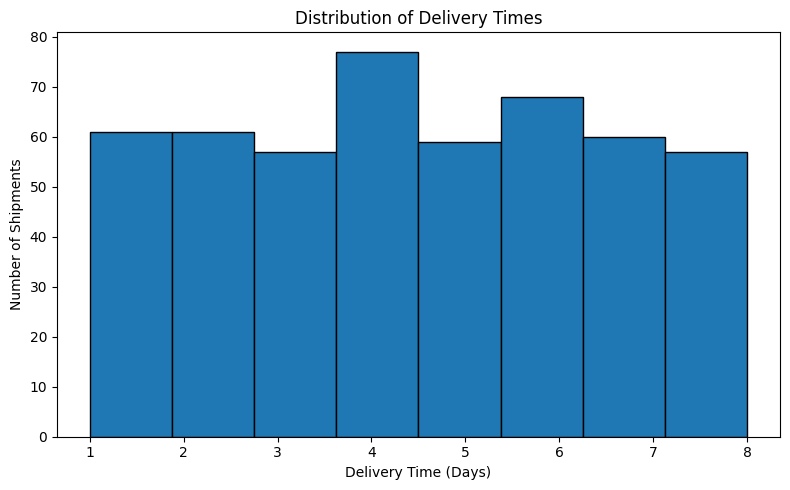

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["Delivery_Time_Days"], bins=8, edgecolor="black")
ax.set(title="Distribution of Delivery Times", xlabel="Delivery Time (Days)", ylabel="Number of Shipments")
fig.tight_layout()
fig.savefig("../visualizations/Delivery_Time_Distribution.png", dpi=220, bbox_inches="tight")
plt.show()


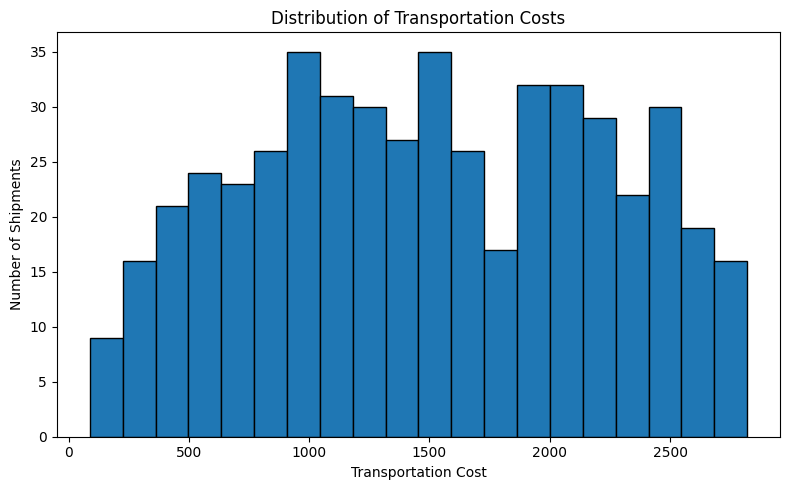

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["Transportation_Cost"], bins=20, edgecolor="black")
ax.set(title="Distribution of Transportation Costs", xlabel="Transportation Cost", ylabel="Number of Shipments")
fig.tight_layout()
fig.savefig("../visualizations/Transportation_Cost_Distribution.png", dpi=220, bbox_inches="tight")
plt.show()


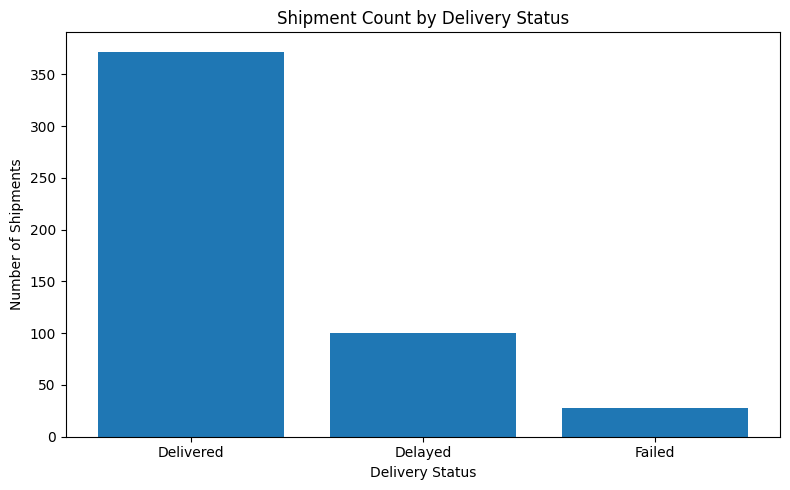

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(status_counts.index, status_counts.values)
ax.set(title="Shipment Count by Delivery Status", xlabel="Delivery Status", ylabel="Number of Shipments")
fig.tight_layout()
fig.savefig("../visualizations/Delivery_Status_Analysis.png", dpi=220, bbox_inches="tight")
plt.show()


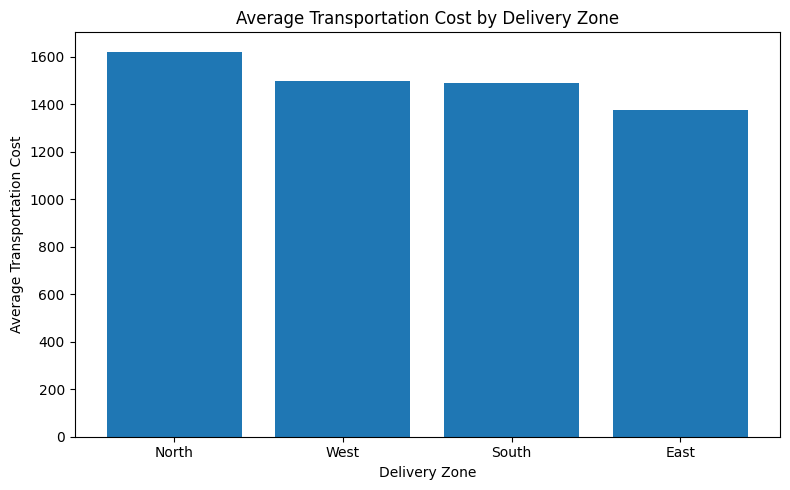

Delivery_Zone
North    1621.92
West     1499.71
South    1491.03
East     1375.38
Name: Transportation_Cost, dtype: float64

In [7]:
zone_cost = df.groupby("Delivery_Zone")["Transportation_Cost"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(zone_cost.index, zone_cost.values)
ax.set(title="Average Transportation Cost by Delivery Zone", xlabel="Delivery Zone", ylabel="Average Transportation Cost")
fig.tight_layout()
fig.savefig("../visualizations/Cost_by_Delivery_Zone.png", dpi=220, bbox_inches="tight")
plt.show()
display(zone_cost.round(2))


## 4. Correlation analysis

,Delivery_Time_Days,Distance_KM,Shipment_Weight_KG,Shipment_Volume,Transportation_Cost
Delivery_Time_Days,1.00,0.02,0.00,0.07,0.02
Distance_KM,0.02,1.00,0.03,0.05,0.99
Shipment_Weight_KG,0.00,0.03,1.00,0.04,0.10
Shipment_Volume,0.07,0.05,0.04,1.00,0.04
Transportation_Cost,0.02,0.99,0.10,0.04,1.00


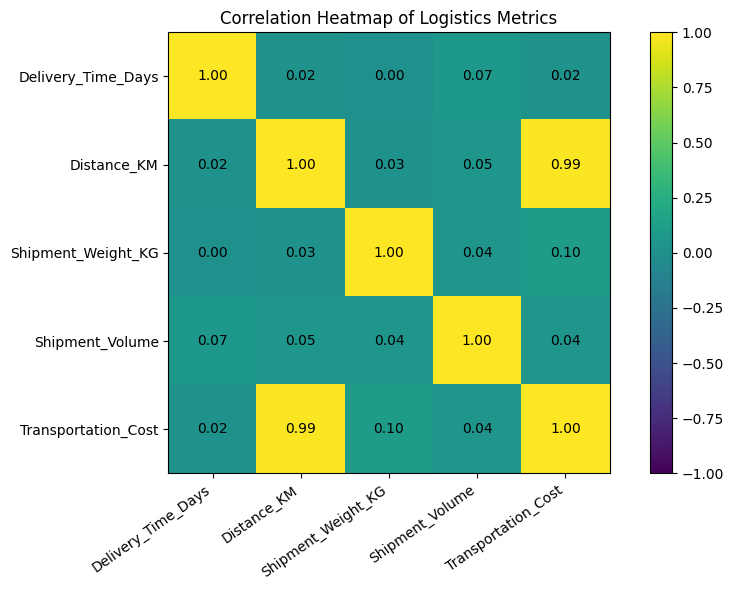

In [8]:
numeric_df = df[["Delivery_Time_Days", "Distance_KM", "Shipment_Weight_KG",
                  "Shipment_Volume", "Transportation_Cost"]]
correlation_matrix = numeric_df.corr()
display(correlation_matrix.round(2))
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(correlation_matrix, vmin=-1, vmax=1)
fig.colorbar(im, ax=ax)
ax.set_xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=35, ha="right")
ax.set_yticks(range(len(correlation_matrix.index)), correlation_matrix.index)
for i in range(len(correlation_matrix.index)):
    for j in range(len(correlation_matrix.columns)):
        ax.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}", ha="center", va="center")
ax.set_title("Correlation Heatmap of Logistics Metrics")
fig.tight_layout()
fig.savefig("../visualizations/Logistics_Correlation_Heatmap.png", dpi=220, bbox_inches="tight")
plt.show()


## 5. Delivery performance by zone

,Total_Shipments,Average_Delivery_Time,Average_Transportation_Cost,Delayed_Shipments,Delay_Rate_Percent
Delivery_Zone,,,,,
East,113,4.75,1375.38,24,21.24
North,129,4.19,1621.92,24,18.60
South,136,4.38,1491.03,29,21.32
West,122,4.66,1499.71,23,18.85


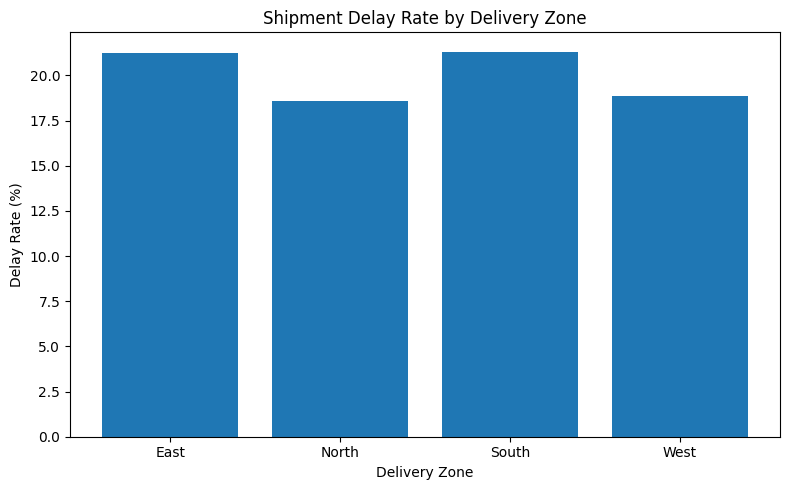

In [9]:
zone_performance = df.groupby("Delivery_Zone").agg(
    Total_Shipments=("Shipment_ID", "count"),
    Average_Delivery_Time=("Delivery_Time_Days", "mean"),
    Average_Transportation_Cost=("Transportation_Cost", "mean"),
    Delayed_Shipments=("Delivery_Status", lambda x: (x == "Delayed").sum())
)
zone_performance["Delay_Rate_Percent"] = (
    zone_performance["Delayed_Shipments"] / zone_performance["Total_Shipments"] * 100
)
display(zone_performance.round(2))
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(zone_performance.index, zone_performance["Delay_Rate_Percent"])
ax.set(title="Shipment Delay Rate by Delivery Zone", xlabel="Delivery Zone", ylabel="Delay Rate (%)")
fig.tight_layout()
fig.savefig("../visualizations/Delay_Rate_by_Zone.png", dpi=220, bbox_inches="tight")
plt.show()


## Interpretation note

The dataset is simulated. The correlation between distance and transportation cost reflects the formula used to generate cost and should not be interpreted as proof of causation in real operations.